In [13]:
import sys
from pathlib import Path

current_dir = Path.cwd()
proj_dir = current_dir.parent.parent.parent.resolve() # get project root directory

print(f"Project directory set to: {proj_dir}")

# Add the project root to the system path to import local modules
sys.path.append(str(proj_dir / "python"))

Project directory set to: E:\Admin\Documents\dermascan


In [14]:
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import cv2
import albumentations as A
import numpy as np

from dataset_manager import DatasetManager
from abcd_algorithms.mask_utils import boundary_extraction

## Load the HAM10000 dataset

In [15]:
# load the dataset manager
dataset_manager = DatasetManager(
    data_dir=str(proj_dir / "data")
)

# load the dataset
# dataset = dataset_manager.load_dataset()
dataset_manager.load_cleaned_metadata()

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [16]:
SIZE = 256
transform = A.Compose(
    [
        A.Resize(height=SIZE, width=SIZE),
    ]
)

## Setup UNet Model

In [17]:
class UNet(nn.Module):
    def __init__(self, n_channels, n_classes):
        super(UNet, self).__init__()
        self.n_channels = n_channels
        self.n_classes = n_classes

        # Contracting path (encoder)
        self.conv1 = nn.Conv2d(self.n_channels, 64, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(64, 128, kernel_size=3, padding=1)
        self.conv3 = nn.Conv2d(128, 256, kernel_size=3, padding=1)
        self.conv4 = nn.Conv2d(256, 512, kernel_size=3, padding=1)
        self.conv5 = nn.Conv2d(512, 1024, kernel_size=3, padding=1)
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

        # Expansive path (decoder)
        self.upconv1 = nn.ConvTranspose2d(1024, 512, kernel_size=2, stride=2)
        self.conv6 = nn.Conv2d(1024, 512, kernel_size=3, padding=1)
        self.upconv2 = nn.ConvTranspose2d(512, 256, kernel_size=2, stride=2)
        self.conv7 = nn.Conv2d(512, 256, kernel_size=3, padding=1)
        self.upconv3 = nn.ConvTranspose2d(256, 128, kernel_size=2, stride=2)
        self.conv8 = nn.Conv2d(256, 128, kernel_size=3, padding=1)
        self.upconv4 = nn.ConvTranspose2d(128, 64, kernel_size=2, stride=2)
        self.conv9 = nn.Conv2d(128, 64, kernel_size=3, padding=1)
        self.conv10 = nn.Conv2d(64, self.n_classes, kernel_size=1)

    def forward(self, x):
        # Contracting path (encoder)
        x1 = F.relu(self.conv1(x))
        x2 = F.relu(self.conv2(self.pool(x1)))
        x3 = F.relu(self.conv3(self.pool(x2)))
        x4 = F.relu(self.conv4(self.pool(x3)))
        x5 = F.relu(self.conv5(self.pool(x4)))

        # Expansive path (decoder)
        x6 = F.relu(self.upconv1(x5))
        x6 = torch.cat([x4, x6], dim=1)
        x6 = F.relu(self.conv6(x6))
        x7 = F.relu(self.upconv2(x6))
        x7 = torch.cat([x3, x7], dim=1)
        x7 = F.relu(self.conv7(x7))
        x8 = F.relu(self.upconv3(x7))
        x8 = torch.cat([x2, x8], dim=1)
        x8 = F.relu(self.conv8(x8))
        x9 = F.relu(self.upconv4(x8))
        x9 = torch.cat([x1, x9], dim=1)
        x9 = F.relu(self.conv9(x9))
        x10 = self.conv10(x9)

        return x10

In [18]:
model = UNet(n_channels=3, n_classes=1).to(DEVICE)

In [19]:
model.load_state_dict(torch.load('./lesion_cutout.pth.tar', map_location=torch.device("cpu"))['state_dict'])

<All keys matched successfully>

## Inference

In [20]:
# Helper methods for cleaning the generated mask
def to_binary_mask(mask, threshold=0.5, use_sigmoid=True):
    """
    Convert model output to a binary uint8 mask (0 or 255).
    """
    mask = mask.astype(np.float32)

    if use_sigmoid:
        mask = 1.0 / (1.0 + np.exp(-mask))

    binary = (mask >= threshold).astype(np.uint8) * 255
    return binary

def get_largest_connected_area(binary_mask):
    """
    Keep only the largest connected component in a binary mask.
    """
    num_labels, labels, stats, _ = cv2.connectedComponentsWithStats(binary_mask, connectivity=8)

    # No foreground found
    if num_labels <= 1:
        return np.zeros_like(binary_mask, dtype=np.uint8)

    largest_label = 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])
    largest = (labels == largest_label).astype(np.uint8) * 255
    return largest


def smooth_mask_edges(mask, morph_kernel_size=7, blur_kernel_size=9):
    """
    Smooth contour using morphology + Gaussian blur.
    Returns a cleaned binary mask (0 or 255).
    """
    if blur_kernel_size % 2 == 0:
        blur_kernel_size += 1  # Gaussian kernel must be odd

    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (morph_kernel_size, morph_kernel_size))

    cleaned = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel)
    cleaned = cv2.morphologyEx(cleaned, cv2.MORPH_OPEN, kernel)

    blurred = cv2.GaussianBlur(cleaned, (blur_kernel_size, blur_kernel_size), sigmaX=0)
    smoothed = ((blurred > 127).astype(np.uint8) * 255)

    return smoothed

def fill_holes_in_mask(mask):
    """
    Fill internal holes in a binary mask (0 or 255).
    """
    mask_u8 = (mask > 0).astype(np.uint8) * 255

    h, w = mask_u8.shape[:2]
    flood = mask_u8.copy()
    flood_fill_buffer = np.zeros((h + 2, w + 2), dtype=np.uint8)

    cv2.floodFill(flood, flood_fill_buffer, seedPoint=(0, 0), newVal=255)

    holes = cv2.bitwise_not(flood)
    filled = cv2.bitwise_or(mask_u8, holes)
    return filled

def resize_mask_to_original(mask, original_size):
    """
    Resize the mask back to the original image size.
    """
    return cv2.resize(mask, (original_size[1], original_size[0]), interpolation=cv2.INTER_NEAREST)

def clean_generated_mask(
    raw_mask,
    threshold=0.5,
    use_sigmoid=True,
    morph_kernel_size=7,
    blur_kernel_size=9,
    resize_to_shape = (256, 256)
):
    """
    Full cleanup pipeline:
    1) binarize
    2) keep largest connected region
    3) Remove holes in the mask by filling the area
    4) Resize to original size
    5) smooth edges
    """
    binary = to_binary_mask(raw_mask, threshold=threshold, use_sigmoid=use_sigmoid)
    largest = get_largest_connected_area(binary)
    filled = fill_holes_in_mask(largest)
    resized = resize_mask_to_original(filled, original_size=resize_to_shape)
    smoothed = smooth_mask_edges(
        resized,
        morph_kernel_size=morph_kernel_size,
        blur_kernel_size=blur_kernel_size
    )
    return smoothed

In [21]:
# Load random sample image
sample_row = dataset_manager.df.loc[dataset_manager.df["image_id"] == Path("ISIC_0024308").stem].iloc[0]
sample_img = cv2.imread(str(proj_dir / "data" / sample_row['image_path']))
sample_img = cv2.cvtColor(sample_img, cv2.COLOR_BGR2RGB)
sample_img = cv2.resize(sample_img, (256, 256), interpolation=cv2.INTER_NEAREST)

# Apply the same transform pipeline used during training
augmentations = transform(image=sample_img)
sample_img = augmentations["image"]

# Convert to tensor
img_tensor = torch.from_numpy(sample_img).float() / 255.0
img_tensor = img_tensor.permute(2, 0, 1).unsqueeze(0).to(DEVICE)

print(img_tensor.shape)
print(img_tensor.numpy(force=True))

torch.Size([1, 3, 256, 256])
[[[[0.9490196  0.9647059  0.96862745 ... 0.9647059  0.9764706
    0.9607843 ]
   [0.96862745 0.9607843  0.9647059  ... 0.9647059  0.9607843
    0.9607843 ]
   [0.95686275 0.9647059  0.9607843  ... 0.9607843  0.9764706
    0.9647059 ]
   ...
   [0.91764706 0.90588236 0.9490196  ... 0.8509804  0.84705883
    0.84313726]
   [0.92156863 0.92941177 0.9490196  ... 0.84705883 0.85490197
    0.84705883]
   [0.9254902  0.92941177 0.9490196  ... 0.85490197 0.84705883
    0.84705883]]

  [[0.6627451  0.6784314  0.6901961  ... 0.64705884 0.65882355
    0.6627451 ]
   [0.6745098  0.6745098  0.68235296 ... 0.65882355 0.654902
    0.6627451 ]
   [0.67058825 0.6862745  0.6745098  ... 0.6392157  0.6627451
    0.6666667 ]
   ...
   [0.65882355 0.65882355 0.69803923 ... 0.5686275  0.57254905
    0.56078434]
   [0.67058825 0.6784314  0.7019608  ... 0.5764706  0.5803922
    0.57254905]
   [0.6745098  0.6627451  0.72156864 ... 0.5803922  0.5647059
    0.57254905]]

  [[0.6980392

In [22]:
# Generate a predicted mask using your trained U-net model
with torch.no_grad():
    generated_mask = model(img_tensor).squeeze().cpu().numpy()
    print(generated_mask)
    print(generated_mask.shape)

generated_mask_stacked = np.stack((generated_mask,)*3, axis=-1) # shape (256, 256, 3)

[[-3.5296009 -4.1597466 -3.92603   ... -4.4833946 -4.7307844 -3.9805114]
 [-4.3420525 -4.73644   -4.4124703 ... -5.2319355 -5.7012615 -5.1413136]
 [-3.9026802 -4.060433  -3.7080495 ... -4.822448  -5.3565145 -4.9734287]
 ...
 [-4.0046253 -4.3475084 -3.835388  ... -2.2430189 -2.9084644 -3.464325 ]
 [-3.9475808 -4.347961  -4.221409  ... -2.8262625 -3.460273  -3.595404 ]
 [-3.5700123 -4.056302  -3.9053445 ... -3.0054848 -3.3689468 -3.1285803]]
(256, 256)


In [23]:
# Apply to existing generated_mask
cleaned_mask = clean_generated_mask( # shape (256, 256)
    generated_mask,
    threshold=0.8,
    use_sigmoid=True,
    morph_kernel_size=7,
    blur_kernel_size=9,
    resize_to_shape=(sample_img.shape[0], sample_img.shape[1])
)

cleaned_mask_stacked = np.stack((cleaned_mask,) * 3, axis=-1) # shape (256, 256, 3)

# Overlay outline on original image
outline = boundary_extraction(cleaned_mask) # shape (256, 256)

overlay_outline = sample_img.copy()
overlay_outline[outline > 0] = [255, 0, 0]

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-7.416616..8.888485].


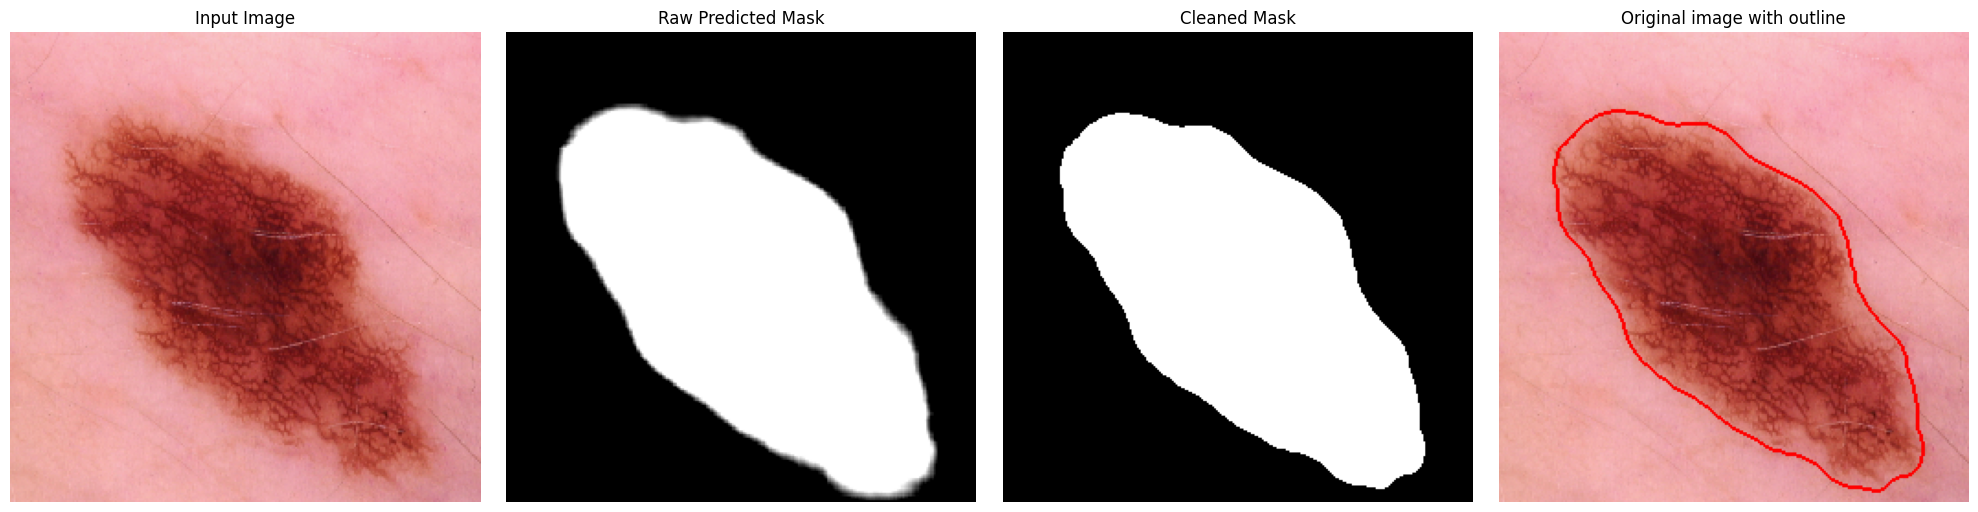

In [24]:
# Preview
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
axes[0].imshow(sample_img)
axes[0].set_title("Input Image")
axes[0].axis("off")

axes[1].imshow(generated_mask_stacked, cmap="gray")
axes[1].set_title("Raw Predicted Mask")
axes[1].axis("off")

axes[2].imshow(cleaned_mask_stacked)
axes[2].set_title("Cleaned Mask")
axes[2].axis("off")

axes[3].imshow(overlay_outline)
axes[3].set_title("Original image with outline")
axes[3].axis('off')
plt.tight_layout()
plt.show()

Compare neural segmentation and Otsu thresholding on selected images

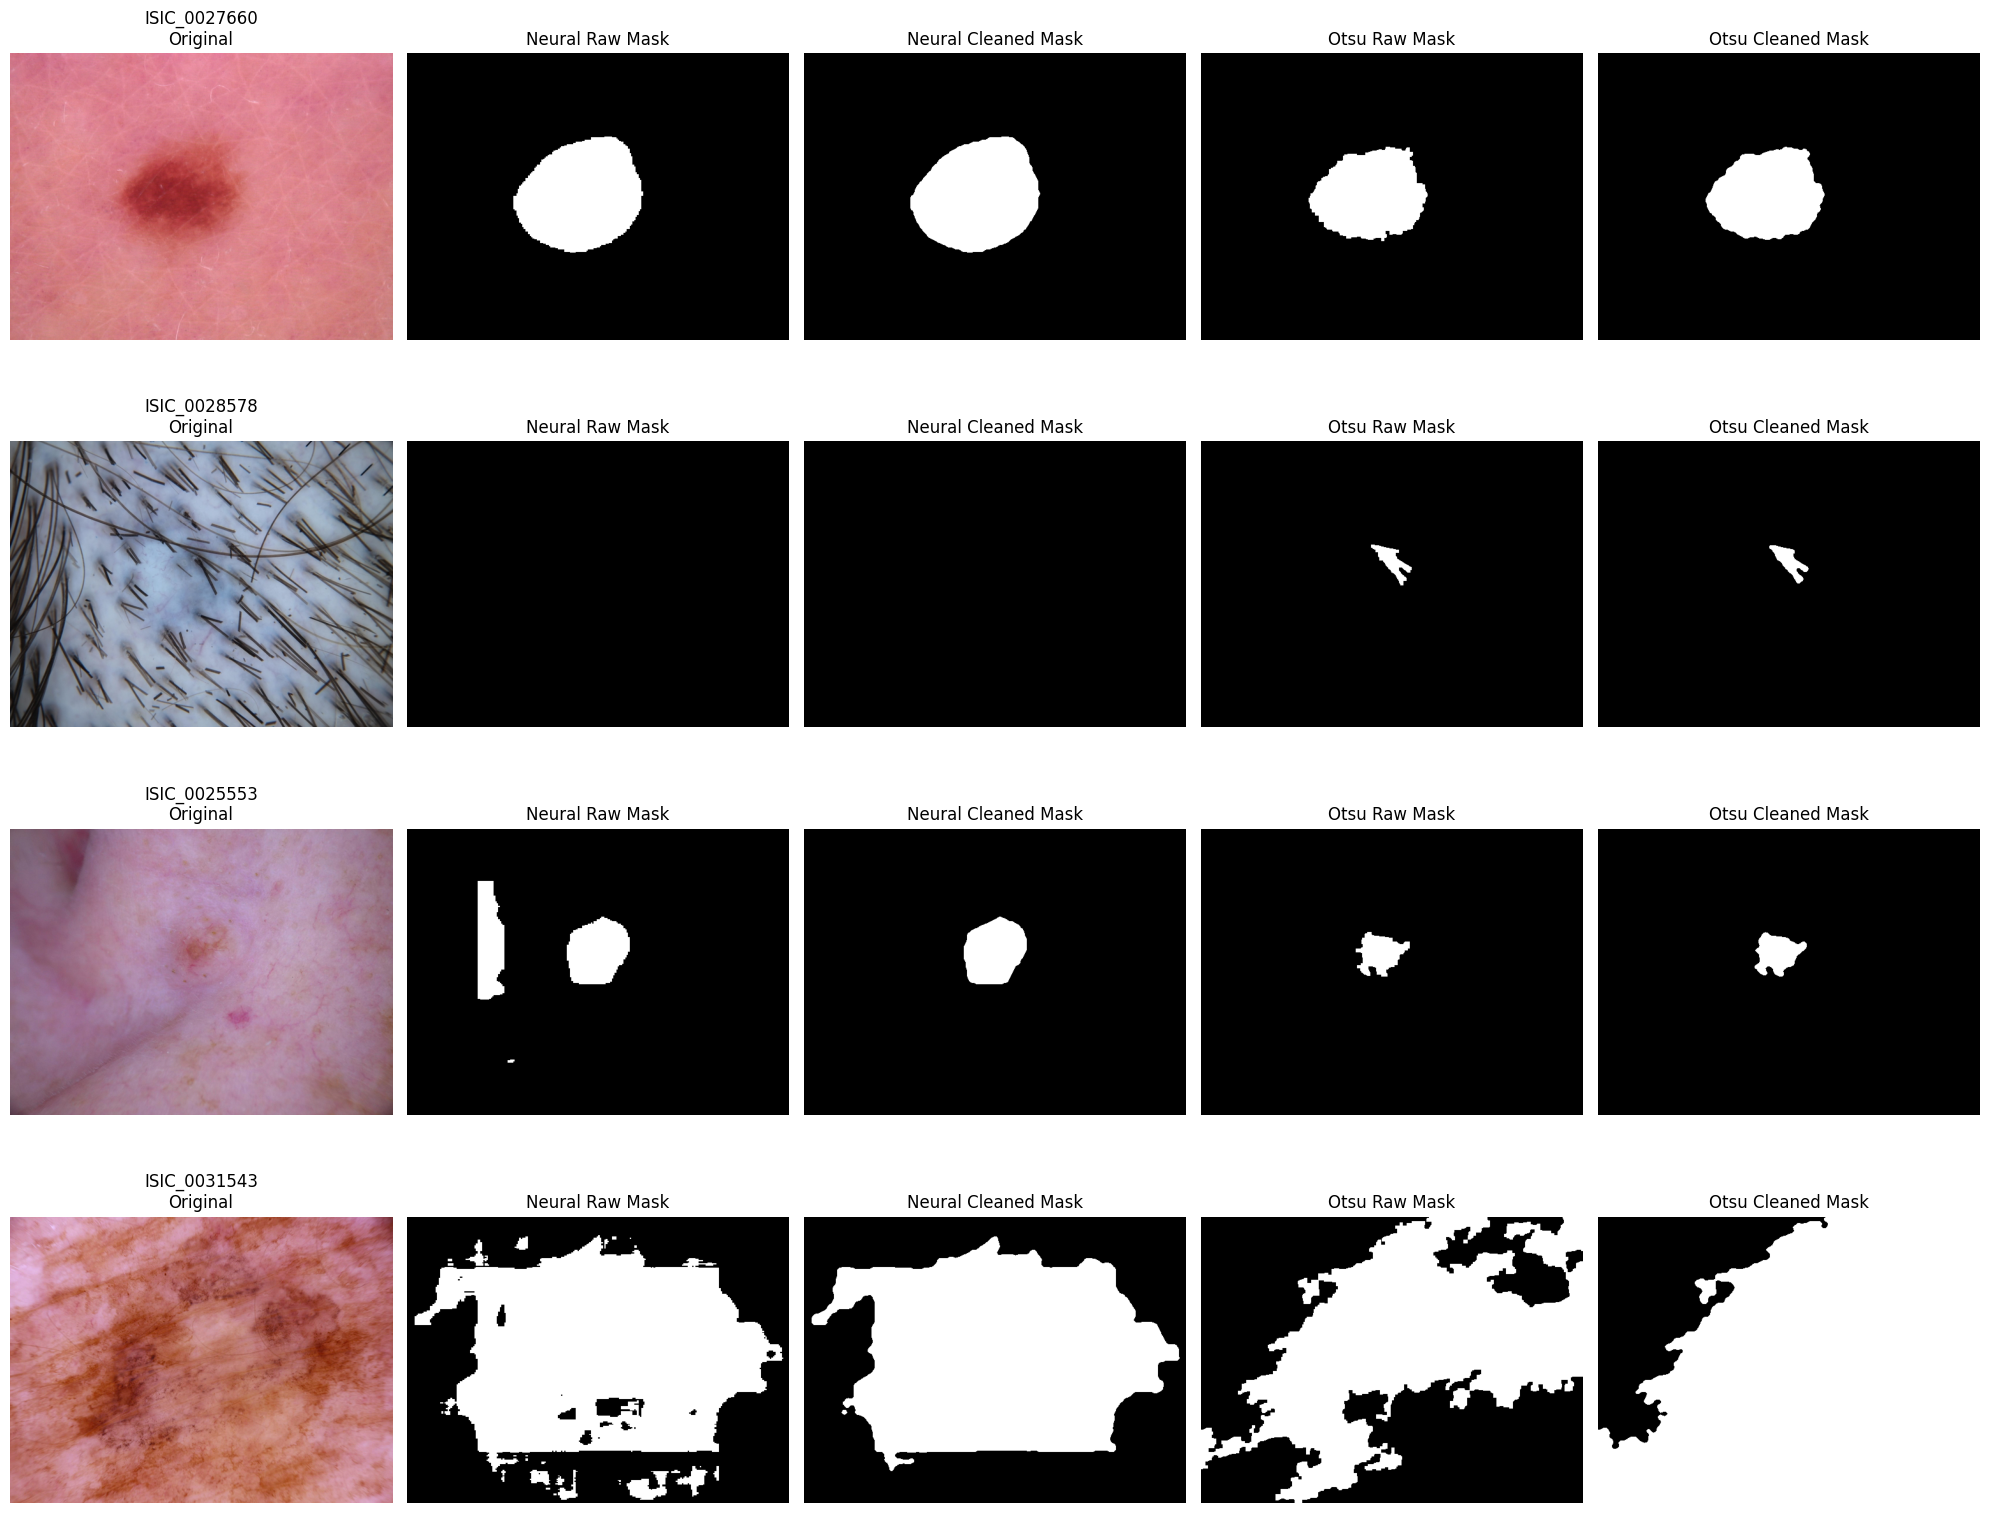

In [25]:
# Compare neural segmentation and Otsu thresholding on selected images
from abcd_algorithms.mask_utils import create_simple_binary_mask

comparison_image_ids = [
    "ISIC_0027660",
    "ISIC_0028578",
    "ISIC_0025553",
    "ISIC_0031543",
]

n_rows = len(comparison_image_ids)
fig, axes = plt.subplots(n_rows, 5, figsize=(20, 4 * n_rows))

for row_idx, image_id in enumerate(comparison_image_ids):
    sample_row = dataset_manager.df.loc[dataset_manager.df["image_id"] == image_id].iloc[0]

    image_bgr = cv2.imread(str(proj_dir / "data" / sample_row["image_path"]))
    image = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
    original_shape = image.shape[:2]

    # Neural model (raw logits -> binary raw mask -> cleaned mask)
    model_input = cv2.resize(image, (SIZE, SIZE), interpolation=cv2.INTER_NEAREST)
    model_input = transform(image=model_input)["image"]

    img_tensor = torch.from_numpy(model_input).float() / 255.0
    img_tensor = img_tensor.permute(2, 0, 1).unsqueeze(0).to(DEVICE)

    with torch.no_grad():
        neural_logits = model(img_tensor).squeeze().cpu().numpy()

    neural_raw_mask = to_binary_mask(neural_logits, threshold=0.7, use_sigmoid=True)
    neural_raw_mask = resize_mask_to_original(neural_raw_mask, original_shape)

    neural_cleaned_mask = clean_generated_mask(
        neural_logits,
        threshold=0.7,
        use_sigmoid=True,
        morph_kernel_size=7,
        blur_kernel_size=9,
        resize_to_shape=original_shape,
    )

    # Otsu method (raw mask -> cleaned mask)
    otsu_raw_mask = create_simple_binary_mask(image)
    otsu_cleaned_mask = clean_generated_mask(
        otsu_raw_mask,
        threshold=0.5,
        use_sigmoid=False,
        morph_kernel_size=7,
        blur_kernel_size=9,
        resize_to_shape=original_shape,
    )

    row_axes = axes[row_idx] if n_rows > 1 else axes

    row_axes[0].imshow(image)
    row_axes[0].set_title(f"{image_id}\nOriginal")
    row_axes[0].axis("off")

    row_axes[1].imshow(neural_raw_mask, cmap="gray")
    row_axes[1].set_title("Neural Raw Mask")
    row_axes[1].axis("off")

    row_axes[2].imshow(neural_cleaned_mask, cmap="gray")
    row_axes[2].set_title("Neural Cleaned Mask")
    row_axes[2].axis("off")

    row_axes[3].imshow(otsu_raw_mask, cmap="gray")
    row_axes[3].set_title("Otsu Raw Mask")
    row_axes[3].axis("off")

    row_axes[4].imshow(otsu_cleaned_mask, cmap="gray")
    row_axes[4].set_title("Otsu Cleaned Mask")
    row_axes[4].axis("off")

plt.tight_layout()
plt.show()